# Notebook 5: Final Test Evaluation

This notebook performs the **final held-out evaluation** for the GQA OPSD experiment.

For each architecture:

- `smolvlm`
- `blip`
- `minicpm`

it evaluates three conditions on the untouched `test.csv`:

1. **Base** — pretrained model, no adaptation
2. **SFT** — best validation-selected LoRA checkpoint
3. **OPSD** — best validation-selected LoRA checkpoint

## Experimental rule

The test set is **not used for checkpoint selection or tuning**.  
`best/` checkpoints were selected using validation BERTScore-F1 in Notebooks 3 and 4.

Primary metric: **BERTScore-F1**  
Secondary metric: **normalised exact match**

The main quantity for RQ1 is:

$$
\Delta_{OPSD-SFT}
=
F1_{OPSD} - F1_{SFT}
$$

RQ2 compares this delta across the three architectures.

The notebook also performs paired per-question analysis and a bootstrap confidence interval for the OPSD-minus-SFT BERTScore-F1 difference.


## Install dependencies

In [29]:
%pip -q install -U "transformers>=5.7,<6" "peft>=0.17" "accelerate>=1.0" "bert-score>=0.3.13" "pandas>=2" "Pillow>=10" "tqdm>=4.66" "matplotlib>=3.8"

/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## Imports, project paths, and settings

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import random
import re
import string

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm
from bert_score import BERTScorer

from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText,
    BlipProcessor,
    BlipForQuestionAnswering,
)

from peft import PeftModel


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# ============================================================
# LOCATE PROJECT ROOT
# ============================================================

def locate_project_root():
    """
    Works when the notebook is run from the project root,
    src/notebooks, or another directory inside the repository.
    """
    start = Path.cwd().resolve()

    candidates = [
        start,
        *start.parents,
    ]

    for candidate in candidates:
        if (
            (candidate / "src" / "data" / "processed").is_dir()
            and (candidate / "src" / "models").is_dir()
            and (candidate / "src" / "results").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root. Expected folders:\n"
        "  src/data/processed\n"
        "  src/models\n"
        "  src/results"
    )


PROJECT_ROOT = locate_project_root()

SRC = PROJECT_ROOT / "src"
DATA = SRC / "data"
PROCESSED = DATA / "processed"
IMAGES = DATA / "images"

MODELS_DIR = SRC / "models"
RESULTS = SRC / "results"

FINAL_RESULTS = (
    RESULTS
    / "final_test"
)

FINAL_RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# MODEL CONFIG
# ============================================================

MODEL_IDS = {
    "smolvlm":
        "HuggingFaceTB/SmolVLM-500M-Instruct",

    "blip":
        "Salesforce/blip-vqa-base",

    "minicpm":
        "openbmb/MiniCPM-V-4.6",
}

MODEL_KEYS = [
    "smolvlm",
    "blip",
    "minicpm",
]

METHODS = [
    "base",
    "sft",
    "opsd",
]

MAX_NEW_TOKENS = 24

BERTSCORE_MODEL = "roberta-large"
BERTSCORE_BATCH_SIZE = 8

# 10,000 is suitable for final reporting.
BOOTSTRAP_SAMPLES = 10_000

# Optional smoke test.
# Keep None for the actual final experiment.
TEST_LIMIT = None


# ============================================================
# DEVICE
# ============================================================

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    MODEL_DTYPE = torch.float16

elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    MODEL_DTYPE = torch.float16

else:
    DEVICE = torch.device("cpu")
    MODEL_DTYPE = torch.float32


print("Project root:", PROJECT_ROOT)
print("Processed:", PROCESSED)
print("Models:", MODELS_DIR)
print("Results:", RESULTS)
print("Final results:", FINAL_RESULTS)
print("Device:", DEVICE)
print("dtype:", MODEL_DTYPE)


/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1030 15:47:51.338000 3784 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Project root: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project
Processed: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/data/processed
Models: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/models
Results: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results
Final results: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/final_test
Device: mps
dtype: torch.float16


## Load and freeze the held-out test split

In [3]:
TEST_CSV = (
    PROCESSED
    / "test.csv"
)

if not TEST_CSV.is_file():
    raise FileNotFoundError(
        f"Missing {TEST_CSV}"
    )


test = pd.read_csv(
    TEST_CSV,
    keep_default_na=False,
)


required_columns = {
    "qa_id",
    "image_id",
    "question",
    "answer",
}


missing = (
    required_columns
    - set(test.columns)
)

if missing:
    raise ValueError(
        f"Missing test columns: {sorted(missing)}"
    )


test["qa_id"] = (
    test["qa_id"]
    .astype(str)
)


# Rebuild local image paths from image_id rather than trusting
# machine-specific absolute paths stored in the CSV.
test["image_path"] = (
    test[
        "image_id"
    ]
    .astype(str)
    .map(
        lambda image_id:
            str(
                IMAGES
                / f"{image_id}.jpg"
            )
    )
)


missing_images = (
    ~test[
        "image_path"
    ]
    .map(
        lambda path:
            Path(path).is_file()
    )
)


if missing_images.any():
    display(
        test.loc[
            missing_images,
            [
                "qa_id",
                "image_id",
                "image_path",
            ],
        ]
        .head(10)
    )

    raise FileNotFoundError(
        f"{int(missing_images.sum())} test images are missing."
    )


# Fingerprint the final held-out split for reproducibility.
fingerprint_payload = "\n".join(
    sorted(
        test[
            "qa_id"
        ]
        .astype(str)
        .tolist()
    )
)

TEST_FINGERPRINT = (
    hashlib.sha256(
        fingerprint_payload.encode(
            "utf-8"
        )
    )
    .hexdigest()[
        :10
    ]
)


if TEST_LIMIT is not None:
    test = (
        test
        .sample(
            n=min(
                TEST_LIMIT,
                len(test),
            ),
            random_state=SEED,
        )
        .reset_index(
            drop=True
        )
    )


print("Test examples:", len(test))
print("Test images:", test.image_id.nunique())
print("Test fingerprint:", TEST_FINGERPRINT)

display(
    test[
        [
            column
            for column in [
                "qa_id",
                "question",
                "answer",
                "structural_type",
                "semantic_type",
                "detailed_type",
            ]
            if column in test.columns
        ]
    ].head()
)


Test examples: 768
Test images: 354
Test fingerprint: 8c20d51345


,qa_id,question,answer,structural_type,semantic_type,detailed_type
0,1287204,Which color are the pants?,white,query,attr,directWhich
1,1287252,Is the sand dry?,no,verify,attr,verifyAttrC
2,1287221,How big is the boot?,small,query,attr,how
3,1171270,Is the brick ground red or blue?,red,choose,attr,chooseAttr
4,1171535,What clothing items are black?,jeans,query,cat,categoryThat


## Verify the saved checkpoints

For SFT and OPSD, Notebook 05 loads only:

```text
src/models/<method>/<model>/seed42/best/
```

The adapter should contain `adapter_config.json` and adapter weights.  
The base condition does not use a checkpoint.


In [32]:
checkpoint_rows = []


for model_key in MODEL_KEYS:

    for method in [
        "sft",
        "opsd",
    ]:

        best_dir = (
            MODELS_DIR
            / method
            / model_key
            / f"seed{SEED}"
            / "best"
        )

        adapter_config = (
            best_dir
            / "adapter_config.json"
        )

        safetensors = (
            best_dir
            / "adapter_model.safetensors"
        )

        binary_weights = (
            best_dir
            / "adapter_model.bin"
        )

        weights_exist = (
            safetensors.is_file()
            or binary_weights.is_file()
        )

        checkpoint_rows.append({
            "model_key":
                model_key,

            "method":
                method,

            "best_dir":
                str(
                    best_dir
                ),

            "adapter_config":
                adapter_config.is_file(),

            "adapter_weights":
                weights_exist,

            "ready":
                (
                    adapter_config.is_file()
                    and weights_exist
                ),
        })


checkpoint_df = pd.DataFrame(
    checkpoint_rows
)

display(
    checkpoint_df
)


not_ready = (
    checkpoint_df[
        ~checkpoint_df[
            "ready"
        ]
    ]
)


if len(not_ready):
    raise FileNotFoundError(
        "One or more best LoRA checkpoints are incomplete. "
        "See the table above."
    )


print(
    "All SFT and OPSD best checkpoints are available."
)


,model_key,method,best_dir,adapter_config,adapter_weights,ready
0,smolvlm,sft,/Users/vishalbhaga/Documents/University/Year 1...,True,True,True
1,smolvlm,opsd,/Users/vishalbhaga/Documents/University/Year 1...,True,True,True
2,blip,sft,/Users/vishalbhaga/Documents/University/Year 1...,True,True,True
3,blip,opsd,/Users/vishalbhaga/Documents/University/Year 1...,True,True,True
4,minicpm,sft,/Users/vishalbhaga/Documents/University/Year 1...,True,True,True
5,minicpm,opsd,/Users/vishalbhaga/Documents/University/Year 1...,True,True,True


All SFT and OPSD best checkpoints are available.


## Evaluation helpers

In [33]:
ARTICLES = re.compile(
    r"\b(a|an|the)\b"
)

PUNCT = str.maketrans(
    "",
    "",
    string.punctuation,
)


def normalize_answer(
    value,
):
    text = (
        str(
            value
        )
        .lower()
        .translate(
            PUNCT
        )
    )

    text = ARTICLES.sub(
        " ",
        text,
    )

    return " ".join(
        text.split()
    )


def open_rgb(
    path,
):
    with Image.open(
        path
    ) as image:
        return (
            image
            .convert(
                "RGB"
            )
            .copy()
        )


def move_batch(
    batch,
):
    moved = {}

    for key, value in batch.items():

        if not torch.is_tensor(
            value
        ):
            moved[
                key
            ] = value
            continue

        if (
            key
            in {
                "pixel_values",
                "pixel_values_videos",
            }
            and value.is_floating_point()
        ):
            moved[
                key
            ] = value.to(
                device=DEVICE,
                dtype=MODEL_DTYPE,
            )

        else:
            moved[
                key
            ] = value.to(
                DEVICE
            )

    return moved


def generic_chat_kwargs(
    model_key,
):
    if model_key == "minicpm":
        return {
            "enable_thinking":
                False,

            "processor_kwargs":
                {
                    "downsample_mode":
                        "4x",

                    "max_slice_nums":
                        1,
                },
        }

    return {}


def load_base_model(
    model_key,
):
    model_id = MODEL_IDS[
        model_key
    ]

    print(
        f"Loading base model: "
        f"{model_key} -> {model_id}"
    )

    if model_key == "blip":

        processor = (
            BlipProcessor
            .from_pretrained(
                model_id
            )
        )

        model = (
            BlipForQuestionAnswering
            .from_pretrained(
                model_id,
                dtype=MODEL_DTYPE,
            )
        )

    else:

        processor = (
            AutoProcessor
            .from_pretrained(
                model_id
            )
        )

        model = (
            AutoModelForImageTextToText
            .from_pretrained(
                model_id,
                dtype=MODEL_DTYPE,
                low_cpu_mem_usage=True,
            )
        )

    model = model.to(
        DEVICE
    )

    model.eval()

    return (
        processor,
        model,
    )


def load_model_for_method(
    model_key,
    method,
):
    processor, base_model = (
        load_base_model(
            model_key
        )
    )

    if method == "base":
        return (
            processor,
            base_model,
        )

    if method == "sft":
        adapter_dir = (
            MODELS_DIR
            / "sft"
            / model_key
            / f"seed{SEED}"
            / "best_repaired"
        )

    else:

        adapter_dir = (
            MODELS_DIR
            / method
            / model_key
            / f"seed{SEED}"
            / "best"
        )

    print(
        f"Loading {method.upper()} adapter:",
        adapter_dir,
    )

    model = (
        PeftModel
        .from_pretrained(
            base_model,
            adapter_dir,
            is_trainable=False,
        )
    )

    model = model.to(
        DEVICE
    )

    model.eval()

    return (
        processor,
        model,
    )


@torch.inference_mode()
def predict_answer(
    model_key,
    processor,
    model,
    image_path,
    question,
):
    """
    Uses the same inference protocol as the SFT/OPSD validation
    notebooks so the final test evaluation is directly comparable
    with checkpoint selection.
    """
    image = open_rgb(
        image_path
    )

    question = str(
        question
    )

    if model_key == "blip":

        inputs = processor(
            images=image,
            text=question,
            return_tensors="pt",
        )

        inputs = move_batch(
            inputs
        )

        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
        )

        return (
            processor
            .decode(
                generated[
                    0
                ],
                skip_special_tokens=True,
            )
            .strip()
        )


    messages = [
        {
            "role":
                "user",

            "content":
                [
                    {
                        "type":
                            "image",

                        "image":
                            image,
                    },
                    {
                        "type":
                            "text",

                        "text":
                            (
                                question
                                + "\nAnswer briefly with only the answer."
                            ),
                    },
                ],
        }
    ]


    kwargs = (
        generic_chat_kwargs(
            model_key
        )
    )


    inputs = (
        processor
        .apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
            **kwargs,
        )
    )

    inputs = move_batch(
        inputs
    )


    generation_kwargs = {
        "max_new_tokens":
            MAX_NEW_TOKENS,

        "do_sample":
            False,
    }


    if model_key == "minicpm":
        generation_kwargs[
            "downsample_mode"
        ] = "4x"


    generated = model.generate(
        **inputs,
        **generation_kwargs,
    )


    trimmed = [
        out_ids[
            len(
                in_ids
            ):
        ]

        for in_ids, out_ids
        in zip(
            inputs[
                "input_ids"
            ],
            generated,
        )
    ]


    return (
        processor
        .batch_decode(
            trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[
            0
        ]
        .strip()
    )


def release_model(
    processor,
    model,
):
    del processor
    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    elif torch.backends.mps.is_available():
        try:
            torch.mps.empty_cache()
        except Exception:
            pass


## Run final test inference

Each model/method pair is cached separately under:

```text
src/results/final_test/<model>/<method>/
```

If a run is interrupted, rerunning the cell resumes from the saved QA IDs.


In [34]:
def evaluate_predictions(
    model_key,
    method,
):
    run_dir = (
        FINAL_RESULTS
        / model_key
        / method
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True,
    )


    predictions_path = (
        run_dir
        / (
            f"test_{TEST_FINGERPRINT}"
            f"_seed{SEED}_predictions.csv"
        )
    )


    current_ids = set(
        test[
            "qa_id"
        ]
        .astype(str)
    )


    records = []
    done = set()


    if predictions_path.is_file():

        cached = pd.read_csv(
            predictions_path,
            keep_default_na=False,
        )

        cached[
            "qa_id"
        ] = (
            cached[
                "qa_id"
            ]
            .astype(str)
        )

        cached = (
            cached[
                cached[
                    "qa_id"
                ]
                .isin(
                    current_ids
                )
            ]
            .copy()
        )

        records = (
            cached
            .to_dict(
                "records"
            )
        )

        done = set(
            cached[
                "qa_id"
            ]
        )

        print(
            f"{model_key}/{method}: "
            f"resuming {len(done)}/{len(test)}"
        )


    processor, model = (
        load_model_for_method(
            model_key,
            method,
        )
    )


    try:

        for row in tqdm(
            test.itertuples(
                index=False
            ),
            total=len(
                test
            ),
            desc=(
                f"{model_key} / "
                f"{method}"
            ),
        ):

            qa_id = str(
                row.qa_id
            )

            if qa_id in done:
                continue


            record = {
                "qa_id":
                    qa_id,

                "image_id":
                    str(
                        row.image_id
                    ),

                "question":
                    str(
                        row.question
                    ),

                "answer":
                    str(
                        row.answer
                    ),

                "prediction":
                    "",

                "error":
                    "",
            }


            try:

                record[
                    "prediction"
                ] = predict_answer(
                    model_key,
                    processor,
                    model,
                    row.image_path,
                    row.question,
                )

            except Exception as exc:

                record[
                    "error"
                ] = (
                    f"{type(exc).__name__}: "
                    f"{str(exc)[:500]}"
                )


            records.append(
                record
            )

            done.add(
                qa_id
            )


            if (
                len(
                    records
                )
                % 25
                == 0
            ):

                pd.DataFrame(
                    records
                ).to_csv(
                    predictions_path,
                    index=False,
                )


            if DEVICE.type == "mps":
                try:
                    torch.mps.empty_cache()
                except Exception:
                    pass


    finally:

        release_model(
            processor,
            model,
        )


    predictions = pd.DataFrame(
        records
    )


    order = {
        str(
            qa_id
        ):
            idx

        for idx, qa_id
        in enumerate(
            test[
                "qa_id"
            ]
        )
    }


    predictions[
        "_order"
    ] = (
        predictions[
            "qa_id"
        ]
        .astype(str)
        .map(
            order
        )
    )


    predictions = (
        predictions
        .sort_values(
            "_order"
        )
        .drop(
            columns=[
                "_order"
            ]
        )
        .reset_index(
            drop=True
        )
    )


    predictions.to_csv(
        predictions_path,
        index=False,
    )


    print(
        "Saved:",
        predictions_path,
    )

    return predictions


all_prediction_files = {}


for model_key in MODEL_KEYS:

    for method in METHODS:

        predictions = (
            evaluate_predictions(
                model_key,
                method,
            )
        )

        all_prediction_files[
            (
                model_key,
                method,
            )
        ] = predictions

        print()


smolvlm/base: resuming 768/768
Loading base model: smolvlm -> HuggingFaceTB/SmolVLM-500M-Instruct


smolvlm / base: 100%|██████████| 768/768 [00:00<00:00, 401899.62it/s]


Saved: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/final_test/smolvlm/base/test_8c20d51345_seed42_predictions.csv

Loading base model: smolvlm -> HuggingFaceTB/SmolVLM-500M-Instruct


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 7733.55it/s]


Loading SFT adapter: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/models/sft/smolvlm/seed42/best_repaired


smolvlm / sft: 100%|██████████| 768/768 [24:47<00:00,  1.94s/it]


... (21 outputs left out)

Loading weights: 100%|██████████| 779/779 [00:05<00:00, 147.38it/s]


Loading OPSD adapter: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/models/opsd/minicpm/seed42/best


minicpm / opsd: 100%|██████████| 768/768 [00:00<00:00, 188983.60it/s]


Saved: /Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/final_test/minicpm/opsd/test_8c20d51345_seed42_predictions.csv



## Score BERTScore-F1 and exact match

In [35]:
# Load BERTScore once for all nine conditions.
print(
    "Loading BERTScore backbone:",
    BERTSCORE_MODEL,
)

bertscore_scorer = BERTScorer(
    model_type=BERTSCORE_MODEL,
    lang="en",
    device=str(
        DEVICE
    ),
    batch_size=BERTSCORE_BATCH_SIZE,
)


metric_rows = []
scored_runs = {}


for model_key in MODEL_KEYS:

    for method in METHODS:

        run_dir = (
            FINAL_RESULTS
            / model_key
            / method
        )


        predictions_path = (
            run_dir
            / (
                f"test_{TEST_FINGERPRINT}"
                f"_seed{SEED}_predictions.csv"
            )
        )


        predictions = pd.read_csv(
            predictions_path,
            keep_default_na=False,
        )

        predictions[
            "qa_id"
        ] = (
            predictions[
                "qa_id"
            ]
            .astype(str)
        )


        valid_mask = (
            predictions[
                "error"
            ]
            .eq("")
            & predictions[
                "prediction"
            ]
            .astype(str)
            .str.strip()
            .ne("")
        )


        evaluated = (
            predictions[
                valid_mask
            ]
            .copy()
            .reset_index(
                drop=True
            )
        )


        if len(
            evaluated
        ) == 0:

            raise RuntimeError(
                f"No valid predictions for "
                f"{model_key}/{method}"
            )


        evaluated[
            "exact_match"
        ] = (
            evaluated[
                "prediction"
            ]
            .map(
                normalize_answer
            )
            .eq(
                evaluated[
                    "answer"
                ]
                .map(
                    normalize_answer
                )
            )
        )


        (
            bert_p,
            bert_r,
            bert_f1,
        ) = (
            bertscore_scorer
            .score(
                evaluated[
                    "prediction"
                ]
                .astype(str)
                .tolist(),

                evaluated[
                    "answer"
                ]
                .astype(str)
                .tolist(),
            )
        )


        evaluated[
            "bertscore_precision"
        ] = (
            bert_p
            .cpu()
            .numpy()
        )

        evaluated[
            "bertscore_recall"
        ] = (
            bert_r
            .cpu()
            .numpy()
        )

        evaluated[
            "bertscore_f1"
        ] = (
            bert_f1
            .cpu()
            .numpy()
        )


        scored_path = (
            run_dir
            / (
                f"test_{TEST_FINGERPRINT}"
                f"_seed{SEED}_scored.csv"
            )
        )


        evaluated.to_csv(
            scored_path,
            index=False,
        )


        metrics = {
            "model_key":
                model_key,

            "method":
                method,

            "test_fingerprint":
                TEST_FINGERPRINT,

            "seed":
                SEED,

            "n_test":
                int(
                    len(
                        test
                    )
                ),

            "n_evaluated":
                int(
                    len(
                        evaluated
                    )
                ),

            "bertscore_model":
                BERTSCORE_MODEL,

            "bertscore_f1":
                float(
                    evaluated[
                        "bertscore_f1"
                    ]
                    .mean()
                ),

            "exact_match":
                float(
                    evaluated[
                        "exact_match"
                    ]
                    .mean()
                ),
        }


        metrics_path = (
            run_dir
            / (
                f"test_{TEST_FINGERPRINT}"
                f"_seed{SEED}_metrics.json"
            )
        )


        with open(
            metrics_path,
            "w",
        ) as handle:

            json.dump(
                metrics,
                handle,
                indent=2,
            )


        metric_rows.append(
            metrics
        )

        scored_runs[
            (
                model_key,
                method,
            )
        ] = evaluated


        print(
            f"{model_key:8s} "
            f"{method:5s} | "
            f"BERTScore-F1="
            f"{metrics['bertscore_f1']:.6f} | "
            f"EM="
            f"{metrics['exact_match']:.6f} | "
            f"n="
            f"{metrics['n_evaluated']}"
        )


metrics_df = (
    pd.DataFrame(
        metric_rows
    )
)


metrics_df.to_csv(
    FINAL_RESULTS
    / (
        f"final_metrics_"
        f"{TEST_FINGERPRINT}"
        f"_seed{SEED}.csv"
    ),
    index=False,
)


display(
    metrics_df[
        [
            "model_key",
            "method",
            "n_evaluated",
            "bertscore_f1",
            "exact_match",
        ]
    ]
)


Loading BERTScore backbone: roberta-large


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 7807.18it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


smolvlm  base  | BERTScore-F1=0.925583 | EM=0.565104 | n=768
smolvlm  sft   | BERTScore-F1=0.971205 | EM=0.691406 | n=768
smolvlm  opsd  | BERTScore-F1=0.925908 | EM=0.569010 | n=768
blip     base  | BERTScore-F1=0.956869 | EM=0.583333 | n=768
blip     sft   | BERTScore-F1=0.972691 | EM=0.705729 | n=768
blip     opsd  | BERTScore-F1=0.956975 | EM=0.583333 | n=768
minicpm  base  | BERTScore-F1=0.979333 | EM=0.790365 | n=768
minicpm  sft   | BERTScore-F1=0.980617 | EM=0.790365 | n=768
minicpm  opsd  | BERTScore-F1=0.980518 | EM=0.795573 | n=768


,model_key,method,n_evaluated,bertscore_f1,exact_match
0,smolvlm,base,768,0.925583,0.565104
1,smolvlm,sft,768,0.971205,0.691406
2,smolvlm,opsd,768,0.925908,0.569010
3,blip,base,768,0.956869,0.583333
4,blip,sft,768,0.972691,0.705729
5,blip,opsd,768,0.956975,0.583333
6,minicpm,base,768,0.979333,0.790365
7,minicpm,sft,768,0.980617,0.790365
8,minicpm,opsd,768,0.980518,0.795573


## Main final comparison — Base vs SFT vs OPSD

This table contains the primary final results.

`OPSD_minus_SFT` directly answers RQ1 for each architecture.


In [36]:
bert_pivot = (
    metrics_df
    .pivot(
        index="model_key",
        columns="method",
        values="bertscore_f1",
    )
    .reindex(
        MODEL_KEYS
    )
)


em_pivot = (
    metrics_df
    .pivot(
        index="model_key",
        columns="method",
        values="exact_match",
    )
    .reindex(
        MODEL_KEYS
    )
)


comparison_rows = []


for model_key in MODEL_KEYS:

    base_f1 = float(
        bert_pivot.loc[
            model_key,
            "base",
        ]
    )

    sft_f1 = float(
        bert_pivot.loc[
            model_key,
            "sft",
        ]
    )

    opsd_f1 = float(
        bert_pivot.loc[
            model_key,
            "opsd",
        ]
    )


    base_em = float(
        em_pivot.loc[
            model_key,
            "base",
        ]
    )

    sft_em = float(
        em_pivot.loc[
            model_key,
            "sft",
        ]
    )

    opsd_em = float(
        em_pivot.loc[
            model_key,
            "opsd",
        ]
    )


    comparison_rows.append({
        "model_key":
            model_key,

        "base_bertscore_f1":
            base_f1,

        "sft_bertscore_f1":
            sft_f1,

        "opsd_bertscore_f1":
            opsd_f1,

        "sft_minus_base_f1":
            sft_f1
            - base_f1,

        "opsd_minus_base_f1":
            opsd_f1
            - base_f1,

        "opsd_minus_sft_f1":
            opsd_f1
            - sft_f1,

        "base_exact_match":
            base_em,

        "sft_exact_match":
            sft_em,

        "opsd_exact_match":
            opsd_em,

        "sft_minus_base_em":
            sft_em
            - base_em,

        "opsd_minus_base_em":
            opsd_em
            - base_em,

        "opsd_minus_sft_em":
            opsd_em
            - sft_em,
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


comparison_df.to_csv(
    FINAL_RESULTS
    / (
        f"rq1_rq2_comparison_"
        f"{TEST_FINGERPRINT}"
        f"_seed{SEED}.csv"
    ),
    index=False,
)


display(
    comparison_df
)


,model_key,base_bertscore_f1,sft_bertscore_f1,opsd_bertscore_f1,sft_minus_base_f1,opsd_minus_base_f1,opsd_minus_sft_f1,base_exact_match,sft_exact_match,opsd_exact_match,sft_minus_base_em,opsd_minus_base_em,opsd_minus_sft_em
0,smolvlm,0.925583,0.971205,0.925908,0.045623,0.000325,-0.045298,0.565104,0.691406,0.569010,0.126302,0.003906,-0.122396
1,blip,0.956869,0.972691,0.956975,0.015822,0.000107,-0.015716,0.583333,0.705729,0.583333,0.122396,0.000000,-0.122396
2,minicpm,0.979333,0.980617,0.980518,0.001284,0.001185,-0.000099,0.790365,0.790365,0.795573,0.000000,0.005208,0.005208


## Paired OPSD vs SFT analysis with bootstrap confidence intervals

Because SFT and OPSD answer the **same test questions**, the most informative comparison is paired.

For each question:

$$
d_i = F1_{OPSD,i} - F1_{SFT,i}
$$

The notebook reports:

- mean and median paired difference;
- fraction of questions where OPSD is better;
- fraction where SFT is better;
- ties;
- 95% bootstrap confidence interval for the mean paired difference.

The bootstrap is performed on **test examples**, not on aggregate scores.


In [37]:
def paired_bootstrap_ci(
    deltas,
    n_bootstrap=10_000,
    confidence=0.95,
    seed=42,
):
    values = np.asarray(
        deltas,
        dtype=float,
    )

    rng = np.random.default_rng(
        seed
    )

    n = len(
        values
    )

    bootstrap_means = np.empty(
        n_bootstrap,
        dtype=float,
    )


    for index in range(
        n_bootstrap
    ):

        sampled = rng.choice(
            values,
            size=n,
            replace=True,
        )

        bootstrap_means[
            index
        ] = sampled.mean()


    alpha = (
        1.0
        - confidence
    )


    lower = float(
        np.quantile(
            bootstrap_means,
            alpha / 2,
        )
    )

    upper = float(
        np.quantile(
            bootstrap_means,
            1
            - alpha / 2,
        )
    )


    return (
        lower,
        upper,
    )


paired_rows = []
paired_frames = {}


for model_key in MODEL_KEYS:

    sft = (
        scored_runs[
            (
                model_key,
                "sft",
            )
        ][
            [
                "qa_id",
                "answer",
                "prediction",
                "exact_match",
                "bertscore_f1",
            ]
        ]
        .rename(
            columns={
                "prediction":
                    "sft_prediction",

                "exact_match":
                    "sft_exact_match",

                "bertscore_f1":
                    "sft_bertscore_f1",
            }
        )
    )


    opsd = (
        scored_runs[
            (
                model_key,
                "opsd",
            )
        ][
            [
                "qa_id",
                "prediction",
                "exact_match",
                "bertscore_f1",
            ]
        ]
        .rename(
            columns={
                "prediction":
                    "opsd_prediction",

                "exact_match":
                    "opsd_exact_match",

                "bertscore_f1":
                    "opsd_bertscore_f1",
            }
        )
    )


    paired = (
        sft
        .merge(
            opsd,
            on="qa_id",
            how="inner",
            validate="one_to_one",
        )
    )


    paired[
        "bertscore_delta"
    ] = (
        paired[
            "opsd_bertscore_f1"
        ]
        - paired[
            "sft_bertscore_f1"
        ]
    )


    paired[
        "exact_match_delta"
    ] = (
        paired[
            "opsd_exact_match"
        ]
        .astype(int)
        - paired[
            "sft_exact_match"
        ]
        .astype(int)
    )


    tolerance = 1e-8


    opsd_better = float(
        (
            paired[
                "bertscore_delta"
            ]
            > tolerance
        )
        .mean()
    )


    sft_better = float(
        (
            paired[
                "bertscore_delta"
            ]
            < -tolerance
        )
        .mean()
    )


    ties = (
        1.0
        - opsd_better
        - sft_better
    )


    ci_lower, ci_upper = (
        paired_bootstrap_ci(
            paired[
                "bertscore_delta"
            ]
            .to_numpy(),

            n_bootstrap=(
                BOOTSTRAP_SAMPLES
            ),

            confidence=0.95,

            seed=SEED,
        )
    )


    paired_rows.append({
        "model_key":
            model_key,

        "n_paired":
            int(
                len(
                    paired
                )
            ),

        "mean_opsd_minus_sft_f1":
            float(
                paired[
                    "bertscore_delta"
                ]
                .mean()
            ),

        "median_opsd_minus_sft_f1":
            float(
                paired[
                    "bertscore_delta"
                ]
                .median()
            ),

        "ci95_lower":
            ci_lower,

        "ci95_upper":
            ci_upper,

        "opsd_better_fraction":
            opsd_better,

        "sft_better_fraction":
            sft_better,

        "tie_fraction":
            ties,

        "opsd_em_better_fraction":
            float(
                (
                    paired[
                        "exact_match_delta"
                    ]
                    > 0
                )
                .mean()
            ),

        "sft_em_better_fraction":
            float(
                (
                    paired[
                        "exact_match_delta"
                    ]
                    < 0
                )
                .mean()
            ),
    })


    paired_path = (
        FINAL_RESULTS
        / (
            f"{model_key}_"
            f"paired_sft_opsd_"
            f"{TEST_FINGERPRINT}"
            f"_seed{SEED}.csv"
        )
    )


    paired.to_csv(
        paired_path,
        index=False,
    )


    paired_frames[
        model_key
    ] = paired


paired_summary_df = (
    pd.DataFrame(
        paired_rows
    )
)


paired_summary_df.to_csv(
    FINAL_RESULTS
    / (
        f"paired_bootstrap_summary_"
        f"{TEST_FINGERPRINT}"
        f"_seed{SEED}.csv"
    ),
    index=False,
)


display(
    paired_summary_df
)


,model_key,n_paired,mean_opsd_minus_sft_f1,median_opsd_minus_sft_f1,ci95_lower,ci95_upper,opsd_better_fraction,sft_better_fraction,tie_fraction,opsd_em_better_fraction,sft_em_better_fraction
0,smolvlm,768,-0.045298,-0.053654,-0.048315,-0.042301,0.182292,0.817708,0.000000,0.071615,0.194010
1,blip,768,-0.015716,0.000000,-0.019205,-0.012259,0.057292,0.212240,0.730469,0.036458,0.158854
2,minicpm,768,-0.000099,0.000000,-0.002629,0.002440,0.083333,0.089844,0.826823,0.066406,0.061198


## RQ1 interpretation helper

RQ1 asks whether OPSD improves multimodal performance compared with conventional SFT.

The decision is based primarily on the sign and magnitude of `OPSD − SFT` BERTScore-F1 and its paired 95% bootstrap interval.

This cell generates a descriptive summary only; it does **not** change any model or experimental choice.


In [38]:
for row in paired_summary_df.itertuples(
    index=False
):

    delta = (
        row.mean_opsd_minus_sft_f1
    )

    lower = (
        row.ci95_lower
    )

    upper = (
        row.ci95_upper
    )


    if (
        lower > 0
    ):
        conclusion = (
            "OPSD outperformed SFT on paired test BERTScore-F1 "
            "with a wholly positive 95% bootstrap interval."
        )

    elif (
        upper < 0
    ):
        conclusion = (
            "SFT outperformed OPSD on paired test BERTScore-F1 "
            "with a wholly negative 95% bootstrap interval."
        )

    else:
        conclusion = (
            "The 95% bootstrap interval crosses zero; "
            "the paired test difference is inconclusive at this level."
        )


    print(
        f"{row.model_key}: "
        f"mean Δ={delta:+.6f}, "
        f"95% CI=[{lower:+.6f}, {upper:+.6f}]"
    )

    print(
        " ",
        conclusion,
    )

    print()


smolvlm: mean Δ=-0.045298, 95% CI=[-0.048315, -0.042301]
  SFT outperformed OPSD on paired test BERTScore-F1 with a wholly negative 95% bootstrap interval.

blip: mean Δ=-0.015716, 95% CI=[-0.019205, -0.012259]
  SFT outperformed OPSD on paired test BERTScore-F1 with a wholly negative 95% bootstrap interval.

minicpm: mean Δ=-0.000099, 95% CI=[-0.002629, +0.002440]
  The 95% bootstrap interval crosses zero; the paired test difference is inconclusive at this level.



## RQ2 interpretation helper

RQ2 compares the OPSD-minus-SFT difference across the three VLM architectures.

A positive value means OPSD did better than SFT; a negative value means SFT did better.


In [39]:
rq2_df = (
    paired_summary_df[
        [
            "model_key",
            "mean_opsd_minus_sft_f1",
            "ci95_lower",
            "ci95_upper",
            "opsd_better_fraction",
            "sft_better_fraction",
        ]
    ]
    .sort_values(
        "mean_opsd_minus_sft_f1",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


display(
    rq2_df
)


best_relative_model = (
    rq2_df.iloc[
        0
    ][
        "model_key"
    ]
)


worst_relative_model = (
    rq2_df.iloc[
        -1
    ][
        "model_key"
    ]
)


print(
    "Largest relative OPSD-vs-SFT result:",
    best_relative_model,
)

print(
    "Smallest relative OPSD-vs-SFT result:",
    worst_relative_model,
)


,model_key,mean_opsd_minus_sft_f1,ci95_lower,ci95_upper,opsd_better_fraction,sft_better_fraction
0,minicpm,-0.000099,-0.002629,0.002440,0.083333,0.089844
1,blip,-0.015716,-0.019205,-0.012259,0.057292,0.212240
2,smolvlm,-0.045298,-0.048315,-0.042301,0.182292,0.817708


Largest relative OPSD-vs-SFT result: minicpm
Smallest relative OPSD-vs-SFT result: smolvlm


## Validation teacher advantage vs final OPSD gain (optional diagnostic)

Notebook 2 stored validation baseline metrics in model-specific result folders.

This section searches for the latest baseline metrics containing:

- `teacher_advantage`
- `exact_match_teacher_advantage`

and compares the validation crop-teacher advantage with final test OPSD-minus-SFT performance.


In [40]:
teacher_rows = []


for model_key in MODEL_KEYS:

    model_result_dir = (
        RESULTS
        / model_key
    )


    metric_files = (
        sorted(
            model_result_dir.glob(
                "gqa_val_*_metrics.json"
            )
        )
        if model_result_dir.is_dir()
        else []
    )


    valid_items = []


    for metric_file in metric_files:

        try:

            with open(
                metric_file,
                "r",
            ) as handle:

                item = json.load(
                    handle
                )


            if (
                "teacher_advantage"
                in item
            ):
                valid_items.append(
                    (
                        metric_file,
                        item,
                    )
                )

        except Exception:
            continue


    if not valid_items:

        print(
            f"No Notebook 02 teacher metrics found for "
            f"{model_key}; skipping."
        )

        continue


    metric_file, item = (
        valid_items[
            -1
        ]
    )


    teacher_rows.append({
        "model_key":
            model_key,

        "teacher_advantage":
            float(
                item[
                    "teacher_advantage"
                ]
            ),

        "exact_match_teacher_advantage":
            float(
                item.get(
                    "exact_match_teacher_advantage",
                    np.nan,
                )
            ),

        "baseline_metrics_file":
            str(
                metric_file
            ),
    })


if teacher_rows:

    teacher_df = (
        pd.DataFrame(
            teacher_rows
        )
        .merge(
            paired_summary_df[
                [
                    "model_key",
                    "mean_opsd_minus_sft_f1",
                ]
            ],
            on="model_key",
            how="left",
        )
    )


    display(
        teacher_df
    )


    teacher_df.to_csv(
        FINAL_RESULTS
        / (
            f"teacher_advantage_vs_opsd_gain_"
            f"{TEST_FINGERPRINT}"
            f"_seed{SEED}.csv"
        ),
        index=False,
    )

else:

    print(
        "No compatible Notebook 02 metrics were found. "
        "This optional section can be skipped."
    )


,model_key,teacher_advantage,exact_match_teacher_advantage,baseline_metrics_file,mean_opsd_minus_sft_f1
0,smolvlm,-0.000670,0.010624,/Users/vishalbhaga/Documents/University/Year 1...,-0.045298
1,blip,0.001884,0.021248,/Users/vishalbhaga/Documents/University/Year 1...,-0.015716
2,minicpm,-0.000265,0.003984,/Users/vishalbhaga/Documents/University/Year 1...,-0.000099


## Final figures

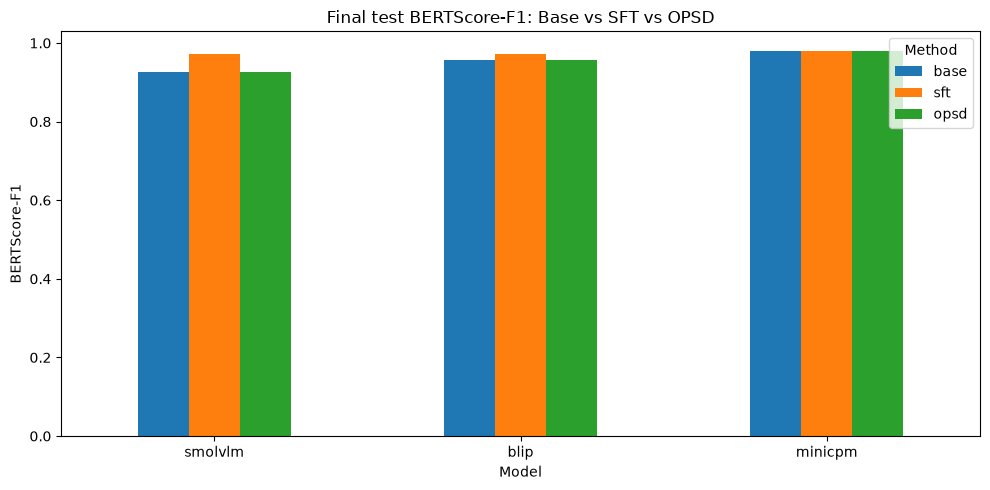

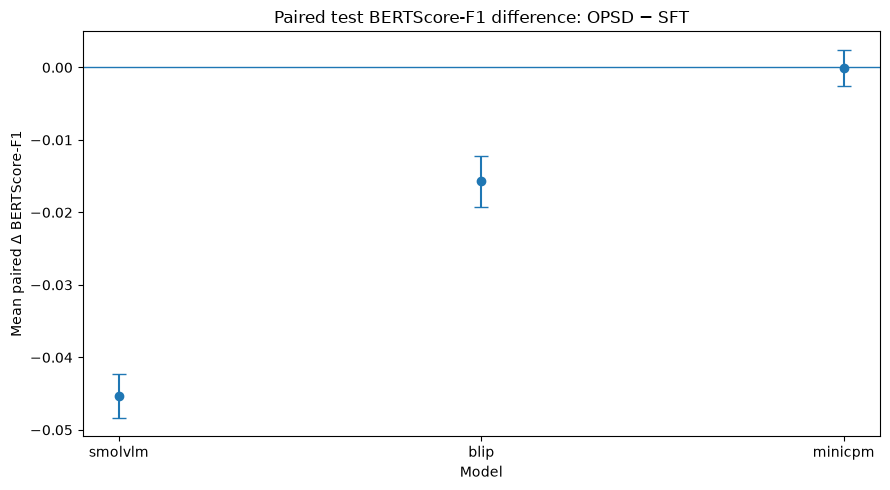

Saved:
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/final_test/final_test_bertscore_by_method.png
/Users/vishalbhaga/Documents/University/Year 1/Semester2/COS802/Project/project/src/results/final_test/opsd_minus_sft_bootstrap_ci.png


In [41]:
# ------------------------------------------------------------
# Figure 1: BERTScore-F1 by model and method
# ------------------------------------------------------------

plot_df = (
    metrics_df
    .pivot(
        index="model_key",
        columns="method",
        values="bertscore_f1",
    )
    .reindex(
        MODEL_KEYS
    )[
        METHODS
    ]
)


ax = plot_df.plot(
    kind="bar",
    figsize=(
        10,
        5,
    ),
)

ax.set_title(
    "Final test BERTScore-F1: Base vs SFT vs OPSD"
)

ax.set_xlabel(
    "Model"
)

ax.set_ylabel(
    "BERTScore-F1"
)

ax.legend(
    title="Method"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

figure1_path = (
    FINAL_RESULTS
    / "final_test_bertscore_by_method.png"
)

plt.savefig(
    figure1_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figure 2: OPSD - SFT paired mean delta with bootstrap CI
# ------------------------------------------------------------

figure_df = (
    paired_summary_df
    .set_index(
        "model_key"
    )
    .reindex(
        MODEL_KEYS
    )
)


means = (
    figure_df[
        "mean_opsd_minus_sft_f1"
    ]
    .to_numpy()
)


lower_errors = (
    means
    - figure_df[
        "ci95_lower"
    ]
    .to_numpy()
)


upper_errors = (
    figure_df[
        "ci95_upper"
    ]
    .to_numpy()
    - means
)


fig, ax = plt.subplots(
    figsize=(
        9,
        5,
    )
)


ax.errorbar(
    MODEL_KEYS,
    means,
    yerr=np.vstack(
        [
            lower_errors,
            upper_errors,
        ]
    ),
    fmt="o",
    capsize=5,
)


ax.axhline(
    0,
    linewidth=1,
)


ax.set_title(
    "Paired test BERTScore-F1 difference: OPSD − SFT"
)

ax.set_xlabel(
    "Model"
)

ax.set_ylabel(
    "Mean paired Δ BERTScore-F1"
)


plt.tight_layout()


figure2_path = (
    FINAL_RESULTS
    / "opsd_minus_sft_bootstrap_ci.png"
)


plt.savefig(
    figure2_path,
    dpi=200,
    bbox_inches="tight",
)


plt.show()


print("Saved:")
print(figure1_path)
print(figure2_path)


## Optional qualitative paired cases

In [42]:
for model_key in MODEL_KEYS:

    paired = (
        paired_frames[
            model_key
        ]
    )


    best_opsd = (
        paired
        .nlargest(
            5,
            "bertscore_delta",
        )[
            [
                "qa_id",
                "answer",
                "sft_prediction",
                "opsd_prediction",
                "sft_bertscore_f1",
                "opsd_bertscore_f1",
                "bertscore_delta",
            ]
        ]
    )


    best_sft = (
        paired
        .nsmallest(
            5,
            "bertscore_delta",
        )[
            [
                "qa_id",
                "answer",
                "sft_prediction",
                "opsd_prediction",
                "sft_bertscore_f1",
                "opsd_bertscore_f1",
                "bertscore_delta",
            ]
        ]
    )


    print(
        f"\n{model_key.upper()} — largest OPSD improvements"
    )

    display(
        best_opsd
    )


    print(
        f"{model_key.upper()} — largest SFT advantages"
    )

    display(
        best_sft
    )



SMOLVLM — largest OPSD improvements


,qa_id,answer,sft_prediction,opsd_prediction,sft_bertscore_f1,opsd_bertscore_f1,bertscore_delta
47,1958283,artichoke,pineapple,Artichoke.,0.844796,0.948700,0.103904
718,1798182,banana,corn,Banana.,0.859191,0.960749,0.101558
43,8959294,street sign,pole,Street sign.,0.861967,0.954765,0.092798
16,7894808,jet,airplane,Jet.,0.859129,0.937265,0.078136
544,311571,playing,dancing,Playing.,0.873293,0.949893,0.076600


SMOLVLM — largest SFT advantages


,qa_id,answer,sft_prediction,opsd_prediction,sft_bertscore_f1,opsd_bertscore_f1,bertscore_delta
504,17494074,no,no,Overcast.,1.0,0.838109,-0.161891
173,2807103,yes,yes,Microoms.,1.0,0.838740,-0.161260
66,2765586,large,large,Small.,1.0,0.854349,-0.145651
192,827028,large,large,Small.,1.0,0.854349,-0.145651
293,71008332,large,large,Small.,1.0,0.854349,-0.145651



BLIP — largest OPSD improvements


,qa_id,answer,sft_prediction,opsd_prediction,sft_bertscore_f1,opsd_bertscore_f1,bertscore_delta
167,14375690,stove,oven,stove,0.830114,1.0,0.169886
534,19794008,nightstand,dresser,nightstand,0.846490,1.0,0.153510
143,6955155,eating,sniffing,eating,0.852037,1.0,0.147963
699,11423248,laptop,computer monitor,laptop,0.865047,1.0,0.134953
16,7894808,jet,fighter jet,jet,0.873210,1.0,0.126790


... (2 outputs left out)


MINICPM — largest OPSD improvements


,qa_id,answer,sft_prediction,opsd_prediction,sft_bertscore_f1,opsd_bertscore_f1,bertscore_delta
47,1958283,artichoke,asparagus,artichoke,0.823407,1.0,0.176593
2,1287221,small,large,small,0.845704,1.0,0.154296
72,1104217,stone,cobblestone,stone,0.855692,1.0,0.144308
378,1430467,laptop,computer mouse,laptop,0.856725,1.0,0.143275
533,19794013,nightstand,bed,nightstand,0.858636,1.0,0.141364


MINICPM — largest SFT advantages


,qa_id,answer,sft_prediction,opsd_prediction,sft_bertscore_f1,opsd_bertscore_f1,bertscore_delta
26,6593082,stop sign,stop sign,yield,1.0,0.813845,-0.186155
59,7325522,long,long,large,1.0,0.831014,-0.168986
293,71008332,large,large,small,1.0,0.845704,-0.154296
335,3454670,large,large,small,1.0,0.845704,-0.154296
648,8799425,small,small,large,1.0,0.845704,-0.154296


## Notes

### Output structure

The notebook writes final outputs under:

```text
src/results/final_test/
```

Key files:

```text
final_metrics_<fingerprint>_seed42.csv
rq1_rq2_comparison_<fingerprint>_seed42.csv
paired_bootstrap_summary_<fingerprint>_seed42.csv

<model>/base/..._predictions.csv
<model>/base/..._scored.csv

<model>/sft/..._predictions.csv
<model>/sft/..._scored.csv

<model>/opsd/..._predictions.csv
<model>/opsd/..._scored.csv

<model>_paired_sft_opsd_<fingerprint>_seed42.csv

final_test_bertscore_by_method.png
opsd_minus_sft_bootstrap_ci.png
```
